# 07 · Interrupted time series and synthetic control

Both answer: *a single intervention happened at time $t_0$; what would have happened without it?*

- **Interrupted time series (ITS):** one series. The counterfactual is the pre-period trend extrapolated forward.
  Assumption: nothing else changed at $t_0$.
- **Synthetic control:** one treated unit plus a pool of untreated **donors**. The counterfactual is a weighted
  average of donors that tracks the treated unit before $t_0$. Assumption: that combination would have kept
  tracking it afterwards.

For your pricing data, ITS fits a single store with a discrete price change; synthetic control fits a chain where
only some stores (or products) changed price.

**You will implement:** segmented regression with Newey–West (HAC) standard errors, synthetic-control weights
by constrained least squares, and placebo (permutation) inference.

**Library checks:** `statsmodels` OLS with `cov_type="HAC"`, and `pysyncon.Synth`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.optimize import minimize
from pysyncon import Synth

import causalsim as cs
from causalsim.plotting import use_style, truth_line, SERIES, INK_2

use_style()

## Part A · Interrupted time series

$y_t = \beta_0 + \beta_1 t + \beta_2\,\text{post}_t + \beta_3 (t-t_0)\,\text{post}_t + \gamma\,\text{weekend}_t + \varepsilon_t$

$\beta_2$ is the immediate level change and $\beta_3$ the change in slope. The errors are autocorrelated, so
ordinary OLS standard errors are too small; we use **Newey–West**:

$\hat S = \sum_t x_t x_t^\top e_t^2 + \sum_{\ell=1}^{L} w_\ell \sum_t (x_t e_t x_{t-\ell}^\top e_{t-\ell} + \text{transpose}),\quad w_\ell = 1-\frac{\ell}{L+1}$

In [2]:
its = cs.its_series(n=400, t0=250, level_change=-8.0, slope_change=0.0, seed=0)
d = its.data
t0 = its.meta["t0"]
t = np.arange(len(d))
post = (t >= t0).astype(float)
X = np.column_stack([np.ones(len(t)), t, post, (t - t0) * post, (d.date.dt.dayofweek >= 5).astype(float)])
y = d.y.to_numpy()


def ols_hac(X, y, maxlags):
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    e = y - X @ beta
    Xe = X * e[:, None]
    S = Xe.T @ Xe
    for lag in range(1, maxlags + 1):
        w = 1 - lag / (maxlags + 1)
        G = Xe[lag:].T @ Xe[:-lag]
        S += w * (G + G.T)
    bread = np.linalg.inv(X.T @ X)
    se_hac = np.sqrt(np.diag(bread @ S @ bread))
    se_naive = np.sqrt(np.diag(e @ e / (len(y) - X.shape[1]) * bread))
    return beta, se_hac, se_naive


beta, se_hac, se_naive = ols_hac(X, y, maxlags=7)
print(f"level change: {beta[2]:.2f}  HAC SE {se_hac[2]:.2f}  (naive SE {se_naive[2]:.2f})   truth {its.truth['level_change']}")
print(f"slope change: {beta[3]:.4f} HAC SE {se_hac[3]:.4f}                       truth {its.truth['slope_change']}")

level change: -8.22  HAC SE 0.67  (naive SE 0.47)   truth -8.0
slope change: 0.0078 HAC SE 0.0067                       truth 0.0


In [3]:
fit = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
np.testing.assert_allclose(beta, fit.params, rtol=1e-8)
np.testing.assert_allclose(se_hac, fit.bse, rtol=1e-8)
assert abs(beta[2] - its.truth["level_change"]) < 3 * se_hac[2]
print("✓ segmented regression and Newey–West SEs match statsmodels HAC")

✓ segmented regression and Newey–West SEs match statsmodels HAC


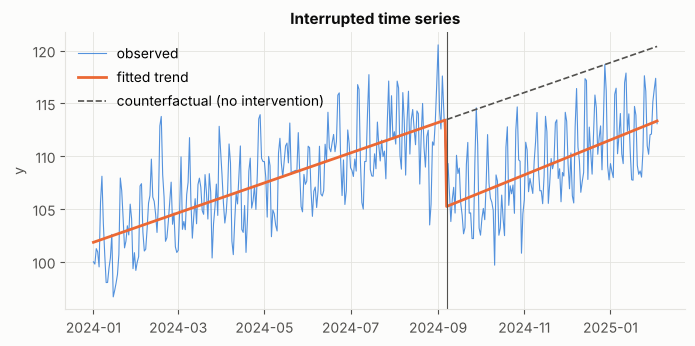

In [4]:
# plot trend lines at the average weekday/weekend mix so the weekly sawtooth doesn't hide the break
avg_weekend = beta[4] * 2 / 7
fitted_trend = X[:, :4] @ beta[:4] + avg_weekend
counterfactual = X[:, :2] @ beta[:2] + avg_weekend  # no intervention terms
fig, ax = plt.subplots()
ax.plot(d.date, y, linewidth=0.8, alpha=0.8, label="observed")
ax.plot(d.date, fitted_trend, linewidth=2, label="fitted trend")
ax.plot(d.date[t0:], counterfactual[t0:], label="counterfactual (no intervention)", **dict(color=INK_2, linestyle="--", linewidth=1.2))
ax.axvline(its.meta["intervention_date"], color=INK_2, linewidth=0.8)
ax.set(title="Interrupted time series", ylabel="y")
ax.legend()
plt.show()

## Part B · Synthetic control

Choose donor weights $w$ to minimise the pre-period fit error, with weights non-negative and summing to one
(so the synthetic unit is an *interpolation* of donors, never an extrapolation):

$$\min_w \sum_{t<t_0}\left(y_{1t} - \sum_j w_j y_{jt}\right)^2 \quad\text{s.t. } w_j\ge 0,\ \sum_j w_j = 1$$

In [5]:
sc = cs.synthetic_control_panel(n_donors=20, n_periods=60, t0=40, effect=5.0, seed=0)
t0s = sc.meta["t0"]
wide = sc.data.pivot(index="period", columns="unit", values="y")
y1, Y0 = wide[0].to_numpy(), wide.drop(columns=0).to_numpy()


def synth_weights(y1_pre, Y0_pre):
    J = Y0_pre.shape[1]
    res = minimize(
        lambda w: np.sum((y1_pre - Y0_pre @ w) ** 2),
        x0=np.full(J, 1 / J),
        method="SLSQP",
        bounds=[(0, 1)] * J,
        constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}],
        options={"ftol": 1e-12, "maxiter": 2_000},
    )
    return res.x


w = synth_weights(y1[:t0s], Y0[:t0s])
synthetic = Y0 @ w
gap = y1 - synthetic
att = gap[t0s:].mean()
print(f"synthetic-control ATT: {att:.3f}   (truth {sc.truth['effect']})")
pd.DataFrame({"estimated w": w, "true w": sc.truth["weights"]}, index=[f"donor {j+1}" for j in range(len(w))]).query("`estimated w` > 0.01 or `true w` > 0.01").round(3)

synthetic-control ATT: 5.067   (truth 5.0)


,estimated w,true w
donor 1,0.000,0.110
donor 2,0.000,0.107
donor 13,0.452,0.783
donor 14,0.159,0.000
donor 15,0.298,0.000
donor 17,0.077,0.000
donor 18,0.014,0.000


The estimated weights differ from the true ones, but the **counterfactual path** is close. With many
donors and noise, the weights are not identified; only the synthetic unit's trajectory is. Don't interpret
individual weights too literally.

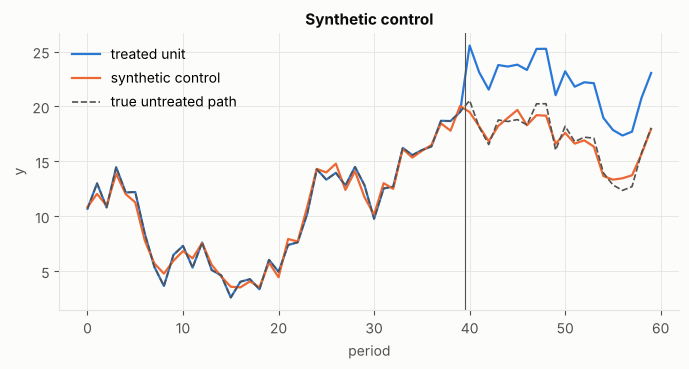

In [6]:
fig, ax = plt.subplots()
ax.plot(wide.index, y1, label="treated unit")
ax.plot(wide.index, synthetic, label="synthetic control")
ax.plot(wide.index, sc.truth["y0_treated"], label="true untreated path", **dict(color=INK_2, linestyle="--", linewidth=1.2))
ax.axvline(t0s - 0.5, color=INK_2, linewidth=0.8)
ax.set(title="Synthetic control", xlabel="period", ylabel="y")
ax.legend()
plt.show()

### Library check: pysyncon

`pysyncon.Synth` (a) **rescales every predictor row by its standard deviation across units**, and (b) by
default also optimises a predictor-importance matrix $V$. To solve the *same* problem as above, pass the
pre-period outcomes as predictors and set `custom_V` to the squared row standard deviations, which undoes
the rescaling. The two solvers then agree up to optimizer tolerance.

In [7]:
pre = wide.index < t0s
X0, X1 = wide.drop(columns=0)[pre], wide[0][pre]
row_sd = pd.concat([X0, X1], axis=1).std(axis=1).to_numpy()

syn = Synth()
syn.fit(X0=X0, X1=X1, Z0=X0, Z1=X1, custom_V=row_sd ** 2)
w_lib = np.asarray(syn.W)
synthetic_lib = Y0 @ w_lib

loss = lambda ww: np.sum((y1[:t0s] - Y0[:t0s] @ ww) ** 2)
print(f"pre-period SSE  scratch {loss(w):.4f}   pysyncon {loss(w_lib):.4f}")
np.testing.assert_allclose(synthetic, synthetic_lib, atol=0.05)
np.testing.assert_allclose(att, (y1 - synthetic_lib)[t0s:].mean(), atol=0.02)
assert abs(att - sc.truth["effect"]) < 0.5
print("✓ synthetic path and ATT match pysyncon (to solver tolerance)")

# default pysyncon behaviour, with V optimised by nested optimisation:
syn_v = Synth()
syn_v.fit(X0=X0, X1=X1, Z0=X0, Z1=X1)
print(f"pysyncon with optimised V: ATT = {(y1 - Y0 @ np.asarray(syn_v.W))[t0s:].mean():.3f}")

pre-period SSE  scratch 11.9802   pysyncon 11.9802
✓ synthetic path and ATT match pysyncon (to solver tolerance)


pysyncon with optimised V: ATT = 5.074


### Inference: in-space placebos

There's one treated unit, so no standard errors in the usual sense. Instead, pretend each donor was treated,
rerun the method, and ask how extreme the real unit's post/pre RMSPE ratio is among the placebos.

treated unit ranks 1 of 21 → permutation p-value = 0.048


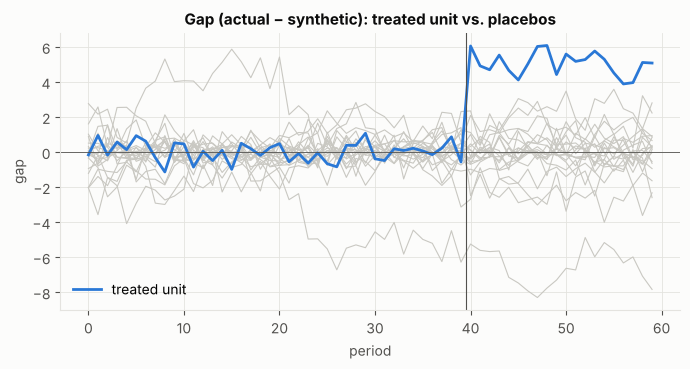

In [8]:
def rmspe_ratio(y_tr, Y_donors, t0):
    ww = synth_weights(y_tr[:t0], Y_donors[:t0])
    g = y_tr - Y_donors @ ww
    return np.sqrt(np.mean(g[t0:] ** 2)) / np.sqrt(np.mean(g[:t0] ** 2)), g


ratios, gaps = {}, {}
all_units = wide.to_numpy()
for j in range(all_units.shape[1]):
    others = np.delete(all_units, j, axis=1)
    ratios[j], gaps[j] = rmspe_ratio(all_units[:, j], others, t0s)

rank = sum(r >= ratios[0] for r in ratios.values())
print(f"treated unit ranks {rank} of {len(ratios)} → permutation p-value = {rank / len(ratios):.3f}")

fig, ax = plt.subplots()
for j, g in gaps.items():
    if j:
        ax.plot(wide.index, g, color="#c9c8c2", linewidth=0.8)
ax.plot(wide.index, gaps[0], color=SERIES[0], linewidth=2, label="treated unit")
ax.axvline(t0s - 0.5, color=INK_2, linewidth=0.8)
ax.axhline(0, color=INK_2, linewidth=0.6)
ax.set(title="Gap (actual − synthetic): treated unit vs. placebos", xlabel="period", ylabel="gap")
ax.legend()
plt.show()

**Exercises**
1. ITS: add an unrelated shock at $t_0$ (e.g. a holiday spike) to the simulator. ITS can't tell it apart from the intervention. Why can synthetic control?
2. ITS: vary `maxlags` from 0 to 30. How do the HAC standard errors behave? Compare with the `ar1` parameter of the simulator.
3. Synthetic control: make the treated unit an *outlier* (scale its loadings by 1.5) so no convex combination fits.
   What happens to the pre-period fit and the estimate? Try `pysyncon.AugSynth`.
4. Build a chain of 15 "stores" by calling `cs.retail_pricing(seed=s)` for different seeds, multiply `price_1` by 0.8
   from day 500 in one store only (recompute its `purch_1` with the known elasticity), and recover the effect with
   synthetic control on weekly `purch_1`.